# Detector de emociones usando Yolo11s y Yolo11-cls

Este cuaderno está enfocado al entrenamiento, evaluación y demostración de un detector de caras + clasificador de emociones. Se ha decidido usar modelos de `ultralytics` por su simpleza y rapidez de entrenamiento.

## Fase 1. Entrenamiento de Yolo11s para detección de caras

### 1.1 Preparación del dataset (`dataset_caras` → `dataset_yolo`)

El dataset de partida (`dataset_caras`) contiene las imágenes en `images/` y sus etiquetas en formato YOLO en `labels/` (una línea por cara: `clase xc yc w h`, coordenadas normalizadas a [0, 1]). Solo existe una clase: `0 = face`.

Pasos:
1. Emparejar cada imagen con su fichero de etiquetas.
2. Dividir aleatoriamente en **train / val / test = 70 / 15 / 15** (con semilla fija para que sea reproducible).
3. Reescalar las imágenes a una resolución fija `IMG_SIZE x IMG_SIZE` mediante *letterbox* (se mantiene la relación de aspecto y se rellena con gris), ajustando las cajas a la nueva geometría. Estirar la imagen directamente a `n x n` deformaría las caras, por eso se usa *letterbox*, que es lo mismo que hace Ultralytics internamente al entrenar.
4. Guardar todo en `dataset_yolo/` con la estructura que espera Ultralytics y generar el `data.yaml`.


In [ ]:
# ===== 1.1.1 Configuración y parámetros previos =====
import random
import shutil
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# --- Configuración ---
SRC_DIR = Path("dataset_caras")      # Dataset original (images/ + labels/)
DST_DIR = Path("dataset_yolo")       # Dataset resultante para YOLO
SEED = 42                            # Semilla para que la división sea reproducible

TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

REESCALAR = True                     # True: guarda las imágenes reescaladas a IMG_SIZE x IMG_SIZE
IMG_SIZE = 640                       # Resolución fija (n x n); 640 es la resolución por defecto de YOLO11
PAD_COLOR = (114, 114, 114)          # Color de relleno del letterbox (el mismo que usa Ultralytics)

CLASS_NAMES = ["face"]               # Única clase del detector

random.seed(SEED)

In [ ]:
# ===== 1.1.2 Emparejamiento de Imagen/Label =====
# Emparejamos cada imagen con su fichero de etiquetas (mismo nombre, extensión .txt)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

images = sorted(p for p in (SRC_DIR / "images").iterdir() if p.suffix.lower() in IMG_EXTS)

pairs, sin_label = [], []
for img_path in images:
    lbl_path = SRC_DIR / "labels" / (img_path.stem + ".txt")
    if lbl_path.exists():
        pairs.append((img_path, lbl_path))
    else:
        sin_label.append(img_path)

print(f"Imágenes encontradas:      {len(images)}")
print(f"Pares imagen/etiqueta:     {len(pairs)}")
print(f"Imágenes sin etiqueta:     {len(sin_label)} (se descartan)")

# Imágenes con fichero de etiquetas vacío = imágenes sin caras (fondo). Se mantienen:
# YOLO las usa como ejemplos negativos, lo que ayuda a reducir falsos positivos.
vacias = sum(1 for _, l in pairs if l.stat().st_size == 0)
print(f"Etiquetas vacías (fondo):  {vacias}")

Imágenes encontradas:      12880
Pares imagen/etiqueta:     12880
Imágenes sin etiqueta:     0 (se descartan)
Etiquetas vacías (fondo):  4


### 1.2 División del dataset 70/15/15

In [ ]:
# ===== 1.2.1 Realiza la división =====
# 1) Separamos el 70 % para train y dejamos el 30 % restante
# 2) Ese 30 % se parte a la mitad -> 15 % val y 15 % test

train_pairs, temp_pairs = train_test_split(pairs, train_size=TRAIN_RATIO, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(
    temp_pairs, test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO), random_state=SEED, shuffle=True
)

splits = {"train": train_pairs, "val": val_pairs, "test": test_pairs}

total = len(pairs)
for nombre, lista in splits.items():
    print(f"{nombre:>5}: {len(lista):6d} imágenes ({100 * len(lista) / total:.1f} %)")

train:   9016 imágenes (70.0 %)
  val:   1932 imágenes (15.0 %)
 test:   1932 imágenes (15.0 %)


In [ ]:
# ===== 1.2.2 Funciones auxiliares para el reescalado y normalización de valores =====
def letterbox(img, size=IMG_SIZE, color=PAD_COLOR):
    """Reescala la imagen a size x size manteniendo la relación de aspecto y rellenando
    los bordes. Devuelve la imagen, el factor de escala y el desplazamiento (pad_x, pad_y)."""
    h, w = img.shape[:2]
    r = size / max(h, w)
    new_w, new_h = round(w * r), round(h * r)
    # INTER_AREA es mejor para reducir; INTER_LINEAR para ampliar
    interp = cv2.INTER_AREA if r < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(img, (new_w, new_h), interpolation=interp)

    pad_x, pad_y = (size - new_w) // 2, (size - new_h) // 2
    out = np.full((size, size, 3), color, dtype=np.uint8)
    out[pad_y:pad_y + new_h, pad_x:pad_x + new_w] = resized
    return out, r, (pad_x, pad_y)


def ajustar_labels(lineas, w=1, h=1, r=1.0, pad=(0, 0), size=1):
    """Limpia las cajas YOLO y las transforma para la imagen con letterbox.

    - Recorta cada caja a los límites de la imagen y descarta las de área nula: el
      dataset original tiene cajas con ancho 0 y alguna con coordenadas > 1, que
      Ultralytics marcaría como etiqueta corrupta (descartando la imagen entera).
    - Pasa las coordenadas normalizadas respecto a la imagen original (w x h) a
      normalizadas respecto a la imagen letterbox (size x size).
    Con los valores por defecto no hay transformación: solo se limpian las cajas."""
    pad_x, pad_y = pad
    nuevas = []
    for linea in lineas:
        partes = linea.split()
        if len(partes) != 5:
            continue  # Línea mal formada
        cls, xc, yc, bw, bh = int(partes[0]), *map(float, partes[1:])

        # Esquinas de la caja recortadas a [0, 1]
        x1, y1 = max(xc - bw / 2, 0.0), max(yc - bh / 2, 0.0)
        x2, y2 = min(xc + bw / 2, 1.0), min(yc + bh / 2, 1.0)
        if x2 <= x1 or y2 <= y1:
            continue  # Caja degenerada (área nula)

        # Normalizado original -> píxeles letterbox -> normalizado nuevo
        x1, x2 = [(x * w * r + pad_x) / size for x in (x1, x2)]
        y1, y2 = [(y * h * r + pad_y) / size for y in (y1, y2)]
        nuevas.append(f"{cls} {(x1 + x2) / 2:.6f} {(y1 + y2) / 2:.6f} {x2 - x1:.6f} {y2 - y1:.6f}")
    return nuevas

In [ ]:
# ===== 1.2.3 Creación de la carpeta destino con images y labels divididos =====

if DST_DIR.exists():
    shutil.rmtree(DST_DIR)

errores, descartadas = [], 0
for split, lista in splits.items():
    (DST_DIR / "images" / split).mkdir(parents=True)
    (DST_DIR / "labels" / split).mkdir(parents=True)

    for img_path, lbl_path in tqdm(lista, desc=split):
        dst_img = DST_DIR / "images" / split / img_path.name
        dst_lbl = DST_DIR / "labels" / split / lbl_path.name
        lineas = lbl_path.read_text().strip().splitlines()

        if REESCALAR:
            img = cv2.imread(str(img_path))
            if img is None:
                errores.append(img_path)
                continue
            h, w = img.shape[:2]
            img_lb, r, pad = letterbox(img)
            cv2.imwrite(str(dst_img), img_lb, [cv2.IMWRITE_JPEG_QUALITY, 95])
            nuevas = ajustar_labels(lineas, w, h, r, pad, IMG_SIZE)
        else:
            # Sin reescalado: se copia la imagen y solo se limpian las cajas
            shutil.copy2(img_path, dst_img)
            nuevas = ajustar_labels(lineas)

        descartadas += len(lineas) - len(nuevas)
        dst_lbl.write_text("\n".join(nuevas) + ("\n" if nuevas else ""))

print(f"Imágenes que no se pudieron leer: {len(errores)}")
print(f"Cajas descartadas (mal formadas o de área nula): {descartadas}")

test: 100%|██████████| 1932/1932 [00:48<00:00, 39.68it/s]

Imágenes que no se pudieron leer: 0
Cajas descartadas (mal formadas o de área nula): 27


In [ ]:
# ===== 1.2.4 Adaptación del fichero de configuración de Yolo al nuevo dataset =====

data_yaml = DST_DIR / "data.yaml"
data_yaml.write_text(
    f"path: {DST_DIR.resolve().as_posix()}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    "\n"
    f"nc: {len(CLASS_NAMES)}\n"
    f"names: {CLASS_NAMES}\n"
)
print(data_yaml.read_text())

path: C:/UNI/4 Curso/VC/repo/practicasVC/P5/dataset_yolo
train: images/train
val: images/val
test: images/test

nc: 1
names: ['face']



train: 9016 imágenes, 9016 etiquetas
  val: 1932 imágenes, 1932 etiquetas
 test: 1932 imágenes, 1932 etiquetas


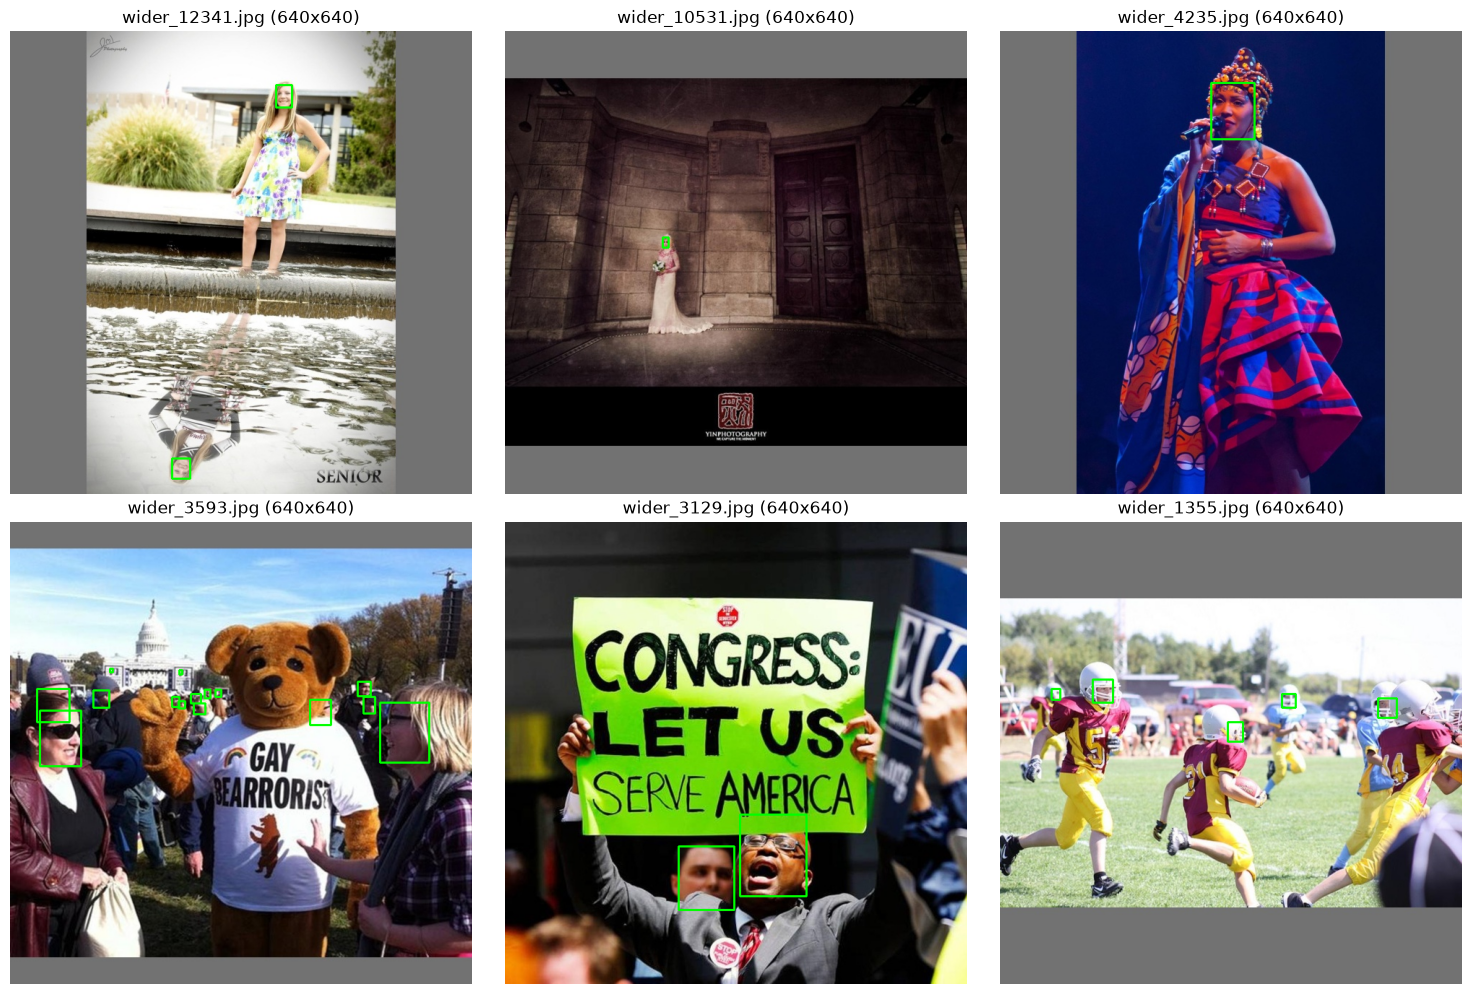

In [ ]:
# ===== 1.2.5 Verificación del emparejamiento, división y visualización =====

# Comprobación: número de imágenes y etiquetas por split (deben coincidir)
for split in splits:
    n_img = len(list((DST_DIR / "images" / split).iterdir()))
    n_lbl = len(list((DST_DIR / "labels" / split).iterdir()))
    print(f"{split:>5}: {n_img} imágenes, {n_lbl} etiquetas")

# Visualización de algunas imágenes de train con sus cajas para verificar que las
# etiquetas siguen bien alineadas después del reescalado
muestras = random.sample(sorted((DST_DIR / "images" / "train").iterdir()), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.ravel(), muestras):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lbl_path = DST_DIR / "labels" / "train" / (img_path.stem + ".txt")
    for linea in lbl_path.read_text().splitlines():
        _, xc, yc, bw, bh = map(float, linea.split())
        x1, y1 = int((xc - bw / 2) * W), int((yc - bh / 2) * H)
        x2, y2 = int((xc + bw / 2) * W), int((yc + bh / 2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    ax.imshow(img)
    ax.set_title(f"{img_path.name} ({W}x{H})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fase 2. Entrenamiento de Yolo11s
Inicio del entrenamiento del modelo Yolo11s para detectar caras.

- **Épocas:** 100
- **Resolución:** **640x640**
- **Batch:** 8 imágenes por lote
- AMP activado
- **Data Augmentation:** por defecto, quitando volteos verticales (Dificulta mucho más el detectar caras)
- **Workers:** 2 hilos de CPU dedicados
- **Paciencia:** 10 épocas antes de una *parada temprana*

### 2.1 Configuración y entrenamiento del detector Yolo

In [ ]:
# ===== 2.1.1 Configuración y parámetros previos =====
import random
from pathlib import Path
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
from pathlib import Path
from ultralytics import YOLO

# --- Configuración ---
DST_DIR = Path("dataset_yolo")       # Dataset resultante para YOLO
SEED = 42                            # Semilla para que la división sea reproducible

random.seed(SEED)

In [ ]:
# ===== 2.1.2 Configuración y carga de los detectores Yolo11s =====
model = YOLO(Path("../models/yolo11s.pt"))

model.train(data=Path("dataset_yolo/data.yaml"), epochs=100, 
imgsz=640, batch=8, amp=True, flipud=0.0,cache=False, workers=2,
name="yolo11s_face_detector", patience=25, device=0, resume=True, save_period=5)

New https://pypi.org/project/ultralytics/8.4.219 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.215  Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_yolo\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1968, mixup=0.0, mode=train, model=ru

### 2.2 Evaluación del Yolo11s entrenado

Se evalúa el mejor modelo (`best.pt`) sobre el split de **test**, que no se ha usado ni para entrenar ni para elegir la mejor época (eso se hizo con val). Así las métricas reflejan cómo se comportará con imágenes nuevas.

> Requiere haber ejecutado la celda de configuración de la Fase 1 (usa `DST_DIR` y `SEED`).

In [ ]:
# ===== 2.2.1 Configuración y carga del detector =====
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import random
import shutil
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

RUN_DIR = Path("../runs/detect/yolo11s_face_detector")       # Carpeta del entrenamiento
TEST_NAME = "yolo11n_face_detector_test"                   # Carpeta donde se guardan las gráficas de test
DATA_YAML = Path("dataset_yolo/data.yaml")

best_model = YOLO(RUN_DIR / "weights" / "best.pt")

# Se borra la evaluación anterior: si la carpeta existe, Ultralytics crearía otra con sufijo (-2, -3...)
shutil.rmtree(RUN_DIR.parent / TEST_NAME, ignore_errors=True)

# Evaluación sobre el split de test: imágenes que el modelo no ha visto ni al entrenar
# ni al elegir la mejor época (para eso se usó val)
test_metrics = best_model.val(
    data=DATA_YAML, split="test", imgsz=640, batch=8, device=0, verbose=False,
    project=str(RUN_DIR.parent.resolve()), name=TEST_NAME,   # Ruta absoluta: con una relativa Ultralytics la anida en runs/detect/
)
TEST_DIR = Path(test_metrics.save_dir)

Ultralytics 8.4.215  Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 269.1±75.5 MB/s, size: 91.1 KB)
val: Scanning C:\UNI\4 Curso\VC\repo\practicasVC\P5\dataset_yolo\labels\test.cache... 1932 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1932/1932  0.0s
WARNING Dataset images contain up to 1750 objects (test=1750), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=1750 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 242/242 2.3it/s 1:460.1ss41
                   all       1932      26821      0.851      0.603      0.679      0.359
Speed: 2.8ms preprocess, 9.4ms infe

#### Resumen del entrenamiento y métricas

- **Precisión**: de las caras detectadas, qué fracción son caras reales.
- **Recall**: de las caras reales, qué fracción se detecta.
- **F1**: media armónica de precisión y recall.
- **mAP50**: precisión media con un solapamiento (IoU) mínimo de 0.5 entre caja predicha y real.
- **mAP50-95**: media del mAP con IoU de 0.5 a 0.95; exige además que las cajas estén bien ajustadas.

In [ ]:
# ===== 2.2.2 Estadísticas del entrenamiento =====
res = pd.read_csv(RUN_DIR / "results.csv")
res.columns = res.columns.str.strip()

# best.pt es la época con mayor mAP50-95 en validación (criterio de Ultralytics)
best = res.loc[res["metrics/mAP50-95(B)"].idxmax()]

def f1(p, r):
    return 2 * p * r / (p + r)

duracion = res["time"].iloc[-1]                     # Segundos acumulados al final de la última época
por_epoca = res["time"].diff().fillna(res["time"].iloc[0])

resumen = pd.DataFrame({
    "Valor": [
        f"{len(res)}",
        f"{int(best['epoch'])}",
        f"{int(duracion // 3600)} h {int(duracion % 3600 // 60)} min",
        f"{por_epoca.mean() / 60:.1f} min (mín. {por_epoca.min() / 60:.1f}, máx. {por_epoca.max() / 60:.1f})",
        f"{sum(test_metrics.speed.values()):.1f} ms/imagen ({test_metrics.speed['inference']:.1f} ms de inferencia)",
    ]},
    index=["Épocas completadas", "Mejor época (best.pt)", "Duración total",
           "Tiempo medio por época", "Velocidad en test (GPU)"],
)

p_val, r_val = best["metrics/precision(B)"], best["metrics/recall(B)"]
p_test, r_test = test_metrics.box.mp, test_metrics.box.mr
metricas = pd.DataFrame(
    {
        "Validación (mejor época)": [p_val, r_val, f1(p_val, r_val),
                                     best["metrics/mAP50(B)"], best["metrics/mAP50-95(B)"]],
        "Test (best.pt)": [p_test, r_test, f1(p_test, r_test),
                           test_metrics.box.map50, test_metrics.box.map],
    },
    index=["Precisión", "Recall", "F1", "mAP50", "mAP50-95"],
).round(3)

display(resumen)
display(metricas)

,Valor
Épocas completadas,100
Mejor época (best.pt),82
Duración total,11 h 47 min
Tiempo medio por época,"7.1 min (mín. 5.6, máx. 22.4)"
Velocidad en test (GPU),15.0 ms/imagen (9.4 ms de inferencia)


,Validación (mejor época),Test (best.pt)
Precisión,0.855,0.851
Recall,0.654,0.603
F1,0.741,0.706
mAP50,0.733,0.679
mAP50-95,0.390,0.359


#### Curvas de entrenamiento

Evolución de las pérdidas (train y validación), de las métricas de validación y de la tasa de aprendizaje a lo largo de las épocas.

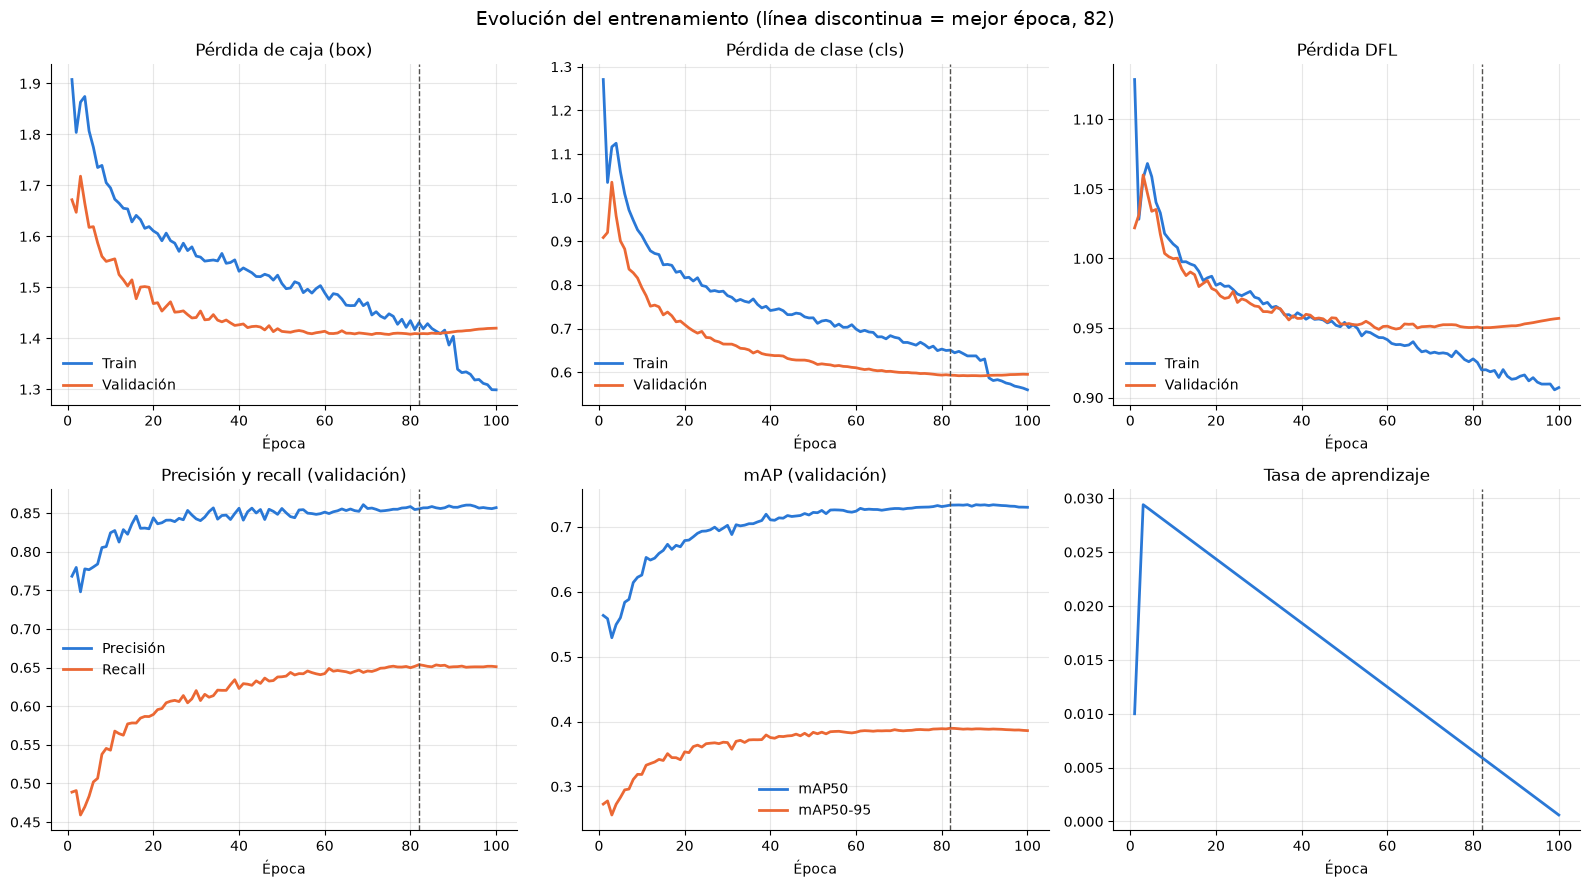

In [ ]:
# ===== 2.2.3 Curvas de entrenamiento =====
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"     # Azul = train, naranja = validación
GRIS = "#52514e"

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
epocas = res["epoch"]

# Fila 1: pérdidas de train y validación
for ax, perdida, titulo in zip(axes[0], ["box_loss", "cls_loss", "dfl_loss"],
                               ["Pérdida de caja (box)", "Pérdida de clase (cls)", "Pérdida DFL"]):
    ax.plot(epocas, res[f"train/{perdida}"], color=TRAIN_COLOR, lw=2, label="Train")
    ax.plot(epocas, res[f"val/{perdida}"], color=VAL_COLOR, lw=2, label="Validación")
    ax.set_title(titulo)

# Fila 2: métricas de validación y tasa de aprendizaje
axes[1, 0].plot(epocas, res["metrics/precision(B)"], color=TRAIN_COLOR, lw=2, label="Precisión")
axes[1, 0].plot(epocas, res["metrics/recall(B)"], color=VAL_COLOR, lw=2, label="Recall")
axes[1, 0].set_title("Precisión y recall (validación)")

axes[1, 1].plot(epocas, res["metrics/mAP50(B)"], color=TRAIN_COLOR, lw=2, label="mAP50")
axes[1, 1].plot(epocas, res["metrics/mAP50-95(B)"], color=VAL_COLOR, lw=2, label="mAP50-95")
axes[1, 1].set_title("mAP (validación)")

axes[1, 2].plot(epocas, res["lr/pg0"], color=TRAIN_COLOR, lw=2)
axes[1, 2].set_title("Tasa de aprendizaje")

for ax in axes.ravel():
    ax.axvline(best["epoch"], color=GRIS, ls="--", lw=1)    # Mejor época
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(frameon=False)
fig.suptitle(f"Evolución del entrenamiento (línea discontinua = mejor época, {int(best['epoch'])})", fontsize=14)
plt.tight_layout()
plt.show()

#### Curvas de test

Gráficas generadas por Ultralytics al evaluar en test: la curva precisión-recall (su área es el mAP50) y cómo varían F1 y recall según el umbral de confianza. El máximo de la curva F1 indica el umbral de confianza más equilibrado.

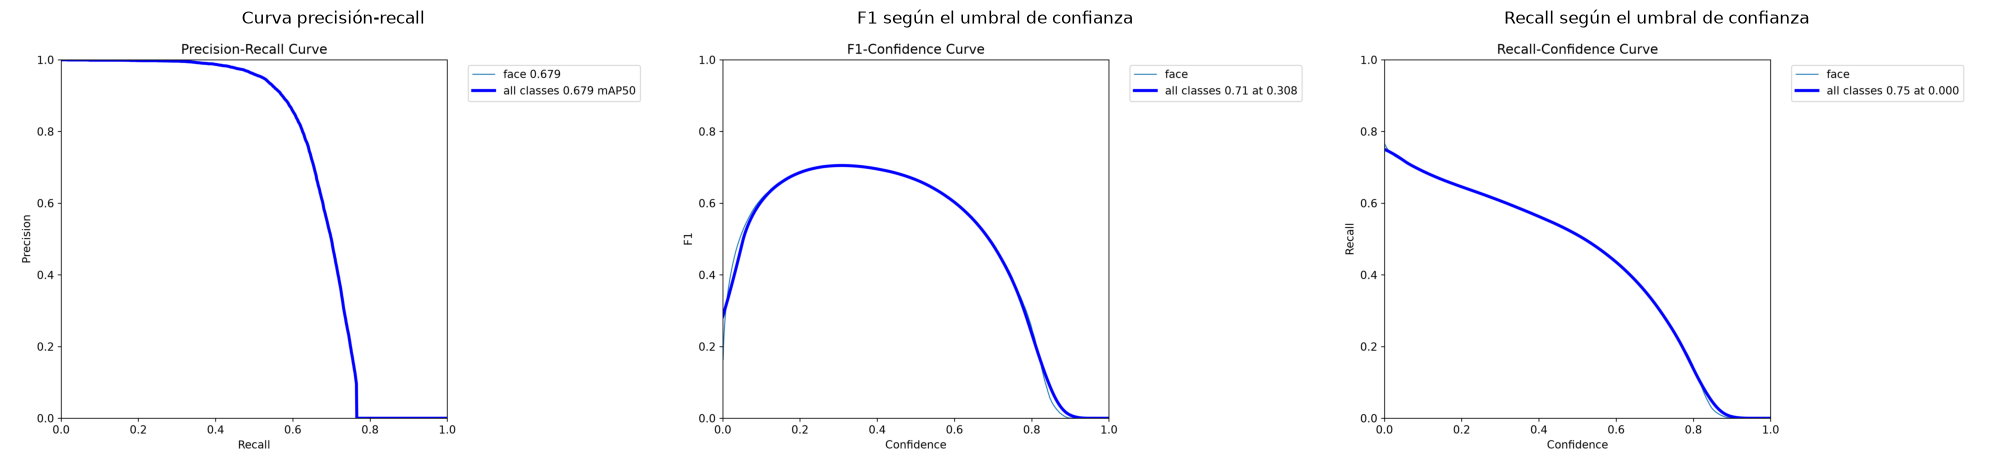

In [ ]:
# ===== 2.2.4 Curvas de test =====
graficas = {
    "Curva precisión-recall": "BoxPR_curve.png",
    "F1 según el umbral de confianza": "BoxF1_curve.png",
    "Recall según el umbral de confianza": "BoxR_curve.png",
}
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (titulo, fichero) in zip(axes, graficas.items()):
    ax.imshow(plt.imread(TEST_DIR / fichero))
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
plt.show()

#### Ejemplos de detecciones en test

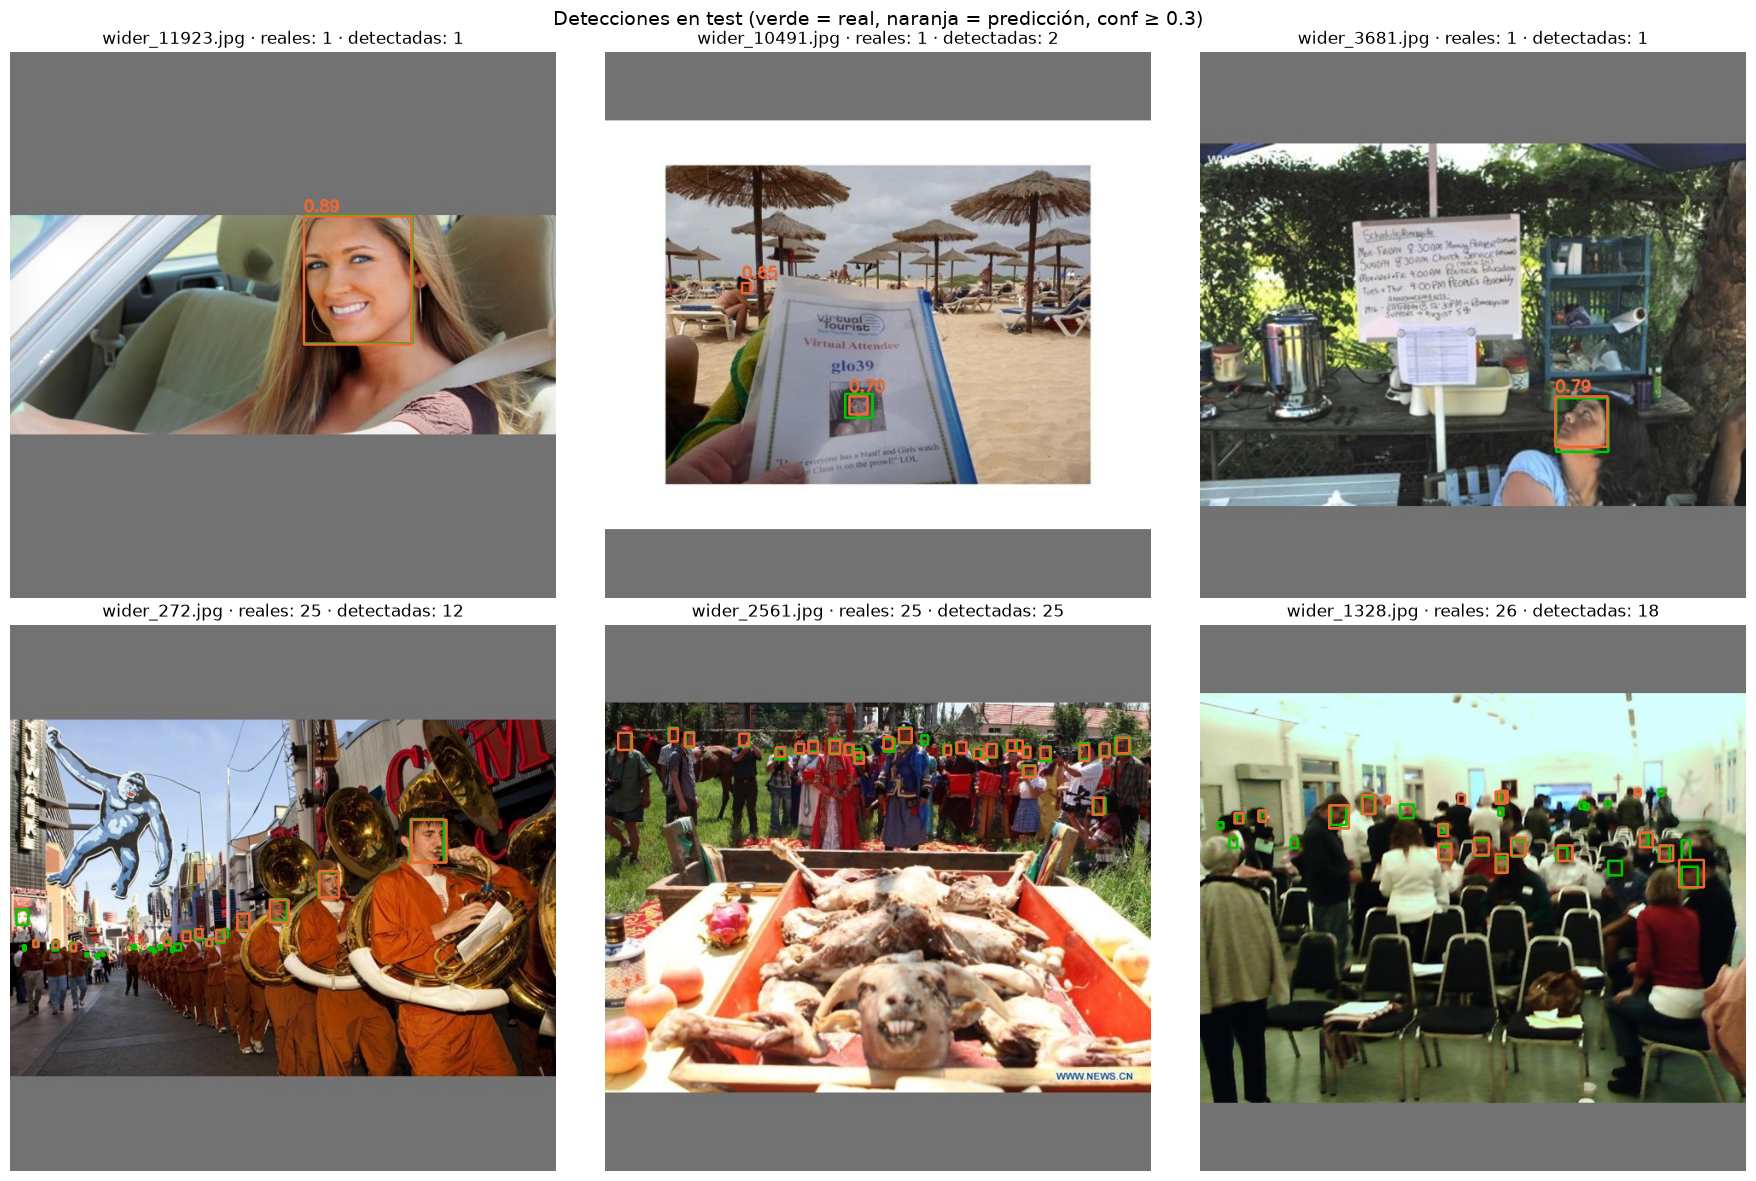

In [ ]:
# ===== 2.2.5 Ejemplos de detecciones =====
# Ejemplos de detecciones en test: verde = caja real (GT), naranja = predicción con su confianza.
# Fila de arriba: imágenes sencillas (1-5 caras). Fila de abajo: escenas con muchas caras (20-60).
GT_COLOR, PRED_COLOR = (0, 200, 0), (52, 104, 235)      # BGR (OpenCV)
CONF = 0.3                                              # Cerca del umbral con mejor F1 en test

def leer_cajas(lbl_path, W, H):
    """Cajas YOLO normalizadas -> píxeles (x1, y1, x2, y2)."""
    cajas = []
    for linea in lbl_path.read_text().splitlines():
        _, xc, yc, bw, bh = map(float, linea.split())
        cajas.append((int((xc - bw / 2) * W), int((yc - bh / 2) * H),
                      int((xc + bw / 2) * W), int((yc + bh / 2) * H)))
    return cajas

test_imgs = sorted((DST_DIR / "images" / "test").iterdir())
lbl_dir = DST_DIR / "labels" / "test"
n_caras = {p: len((lbl_dir / f"{p.stem}.txt").read_text().splitlines()) for p in test_imgs}
random.seed(SEED)
ejemplos = (random.sample([p for p, n in n_caras.items() if 1 <= n <= 5], 3)
            + random.sample([p for p, n in n_caras.items() if 20 <= n <= 60], 3))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (img_path, r) in zip(axes.ravel(), zip(ejemplos, best_model.predict(ejemplos, conf=CONF, verbose=False))):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]
    gt = leer_cajas(lbl_dir / f"{img_path.stem}.txt", W, H)
    for x1, y1, x2, y2 in gt:
        cv2.rectangle(img, (x1, y1), (x2, y2), GT_COLOR, 2)
    for (x1, y1, x2, y2), conf in zip(r.boxes.xyxy.int().tolist(), r.boxes.conf.tolist()):
        cv2.rectangle(img, (x1, y1), (x2, y2), PRED_COLOR, 2)
        if len(gt) <= 5:  # En escenas con muchas caras la confianza taparía la imagen
            cv2.putText(img, f"{conf:.2f}", (x1, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, PRED_COLOR, 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{img_path.name} · reales: {len(gt)} · detectadas: {len(r.boxes)}")
    ax.axis("off")
fig.suptitle(f"Detecciones en test (verde = real, naranja = predicción, conf ≥ {CONF})", fontsize=14)
plt.tight_layout()
plt.show()

#### Conclusiones

- **Precisión alta y estable (≈0.85 en val y test)**: cuando el modelo detecta una cara, casi siempre acierta.
- **El recall es la principal limitación (0.65 en val, 0.60 en test)**: se escapan sobre todo las caras muy pequeñas o tapadas de las escenas con mucha gente. El split de test tiene más caras (26 821 frente a 22 840 en val) y algunas imágenes con cientos de ellas, lo que explica que baje algo respecto a validación.
- **Las curvas muestran un ligero sobreajuste al final**: la pérdida de validación se estabiliza hacia la época 60 y sube un poco en las últimas, mientras que la de train sigue bajando (el salto hacia la época 90 es el cierre del *mosaic*). Por eso la mejor época es la 82 y no la 100.
- **Para el detector de emociones es suficiente**: con caras grandes y de frente (como las de una webcam) las detecciones tienen confianzas de 0.8-0.9, y la inferencia tarda unos 8 ms por imagen en GPU.

## Fase 3 Entrenamiento del Yolo11s-cls como detector de emociones

In [ ]:
# --- Entrenamiento del clasificador Yolo11s ---
import random
from pathlib import Path
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
from pathlib import Path
from ultralytics import YOLO

# --- Configuración ---
DST_DIR = Path("dataset_yolo")       # Dataset resultante para YOLO
SEED = 42                            # Semilla para que la división sea reproducible
random.seed(SEED)


model = YOLO(Path("../models/yolo11s-cls.pt"))
model.train(data=Path("dataset_emociones"), epochs=50, 
imgsz=48, batch=64, amp=True, flipud=0.0,cache=False, workers=2,
name="yolo11s-cls_emotion_detector", patience=10, device=0) 

Ultralytics 8.4.215  Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_emociones, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=48, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=models\yolo11s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s-cls_emotion_detector, nbs=64,

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000002DFEDCD8E90>
curves: []
curves_results: []
fitness: 0.8405544757843018
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.6884925961494446, 'metrics/accuracy_top5': 0.9926163554191589, 'fitness': 0.8405544757843018}
save_dir: WindowsPath('C:/UNI/4 Curso/VC/repo/practicasVC/P5/runs/classify/yolo11s-cls_emotion_detector')
speed: {'preprocess': 0.021932293117761847, 'inference': 0.1546127751462934, 'loss': 0.00010416550557402689, 'postprocess': 0.00020123990015947737}
top1: 0.6884925961494446
top5: 0.9926163554191589

## Fase 4 Uso del detector y clasificador en tiempo real
### 4.1 Configuración y carga de detector y Clasificador Yolo11s

In [1]:
# ===== 4.1.1 Configuración y carga de los detectores Yolo11s =====
import os
import random
from pathlib import Path
from utils import *
import numpy as np
import cv2
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
from ultralytics import YOLO
import time
import mediapipe as mp


classifier = YOLO(Path("../runs/classify/yolo11s-cls_emotion_detector/weights/best.pt"))
detector = YOLO(Path("../runs/detect/yolo11s_face_detector/weights/best.pt"))

pygame 2.6.1 (SDL 2.28.4, Python 3.11.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


### 4.2 Carga de modelo de detección de caras y manos (Mediapipe)

In [2]:
# ===== 4.2.1 Carga de Mediapipe Handlandmaker =====
BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options_hand = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="../models/hand_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_hands=2,
)

In [3]:
# ===== 4.2.2 Carga de Mediapipe Facelandmaker =====
# Se usa para el emote facial del beso mediante los blendshapes.
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions

options_face = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="../models/face_landmarker.task"),
    running_mode=VisionRunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True,
)

### 4.3 Prueba en video con webcam

- Si se pulsa la `e` se muestra/oculta la imagen del hamster
- Si se pulsa la `r` se muestra/oculta los landmarks del Mediapipe
- Si se pulsa la `s` se activa/silencia el sonido
- Pulsa `ESC` para salir

In [4]:
# ===== 4.2 Prueba de vídeo en tiempo real (emotes + emociones) =====
# Por cada frame: se detecta la cara con YOLO; si se reconoce un emote (manos o cara) se pega su
# hámster sobre la cara; si no, se usa la emoción más probable del clasificador.

LANDMARK = False        # Estado inicial de los landmarks (se puede cambiar en vivo con la "r")
COOLDOWN_SONIDO = 8.0     # Segundos mínimos entre dos sonidos
DURACION_SONIDO = 6.0     # Segundos máximos que suena cada audio (se corta al pasar este tiempo)

# Carga previa de las imágenes de cada emoción y de cada emote
hamsters = cargar_hamsters(list(classifier.names.values()) + EMOTES)
# Sonidos: suena uno aleatorio de hamster_sounds/<etiqueta>/ cada vez que cambia la emoción o el emote
sonidos = ReproductorSonidos(list(classifier.names.values()) + EMOTES,
                             cooldown=COOLDOWN_SONIDO, duracion_max=DURACION_SONIDO)
sonidos.alternar_silencio() #empieza silenciado
vid = cv2.VideoCapture(0)
suavizar = Suavizador()
etiqueta_actual, hamster_actual = None, None
ts_prev = -1
mostrar_hamster = True      # Tecla "e"
mostrar_landmarks = LANDMARK   # Tecla "r"

with HandLandmarker.create_from_options(options_hand) as landmarker_hand, \
     FaceLandmarker.create_from_options(options_face) as landmarker_face:
    while True:
        ret, img = vid.read()
        if not ret:
            print("No se ha podido leer un frame de la cámara")
            break
        h_img, w_img = img.shape[:2]

        # Detección de caras, se elige la primera cara detectada
        faces = detector(img, verbose=False)[0]
        if len(faces.boxes) > 0:
            x1, y1, x2, y2 = faces.boxes.xyxy[0].int().tolist()
            x1, y1 = max(x1, 0), max(y1, 0)
            x2, y2 = min(x2, w_img), min(y2, h_img)
            cara = img[y1:y2, x1:x2]

            if cara.size > 0:
                # --- 1) Emotes: MediaPipe sobre el frame ORIGINAL (antes de pegar el hámster) ---
                ts = max(int(time.time() * 1000), ts_prev + 1)    # El modo VIDEO exige timestamps crecientes
                ts_prev = ts
                mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
                res_manos = landmarker_hand.detect_for_video(mp_image, ts)
                res_cara = landmarker_face.detect_for_video(mp_image, ts)

                manos = [mano_a_pixeles(m, w_img, h_img) for m in res_manos.hand_landmarks]
                blend = blendshapes_dict(res_cara)
                emote = suavizar(elegir_emote(emotes_manos(manos, (x1, y1, x2, y2))
                                              | emotes_cara(blend)))

                # --- 2) Si no hay emote, emoción del clasificador ---
                if emote is not None:
                    etiqueta, texto = emote, f"emote: {emote}"
                else:
                    res = classifier(cara, verbose=False)[0]
                    etiqueta = res.names[res.probs.top1]
                    texto = f"{etiqueta} {float(res.probs.top1conf):.2f}"

                # Solo se elige un hámster aleatorio nuevo cuando cambia la etiqueta (evita parpadeo)
                if etiqueta != etiqueta_actual:
                    etiqueta_actual = etiqueta
                    hamster_actual = random.choice(hamsters[etiqueta]) if hamsters.get(etiqueta) else None
                sonidos.actualizar(etiqueta)    # Suena si la etiqueta difiere de la última que sonó y no hay cooldown

                if mostrar_hamster and hamster_actual is not None:
                    pegar_imagen(img, hamster_actual, x1, y1, x2, y2)
                color = (255, 0, 255) if emote else (0, 255, 0)     # Magenta = emote, verde = emoción
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                dibujar_texto(img, texto, (x1, max(y1 - 10, 15)), color)

                if mostrar_landmarks:
                    dibujar_cara(img, res_cara, w_img, h_img)
                    for p in manos:
                        dibujar_mano(img, p)
                    dibujar_texto(img, f"mouthPucker {blend.get('mouthPucker', 0):.2f}", (10, 25), (255, 255, 0))

        dibujar_texto(img, f"[e] hamster: {'ON' if mostrar_hamster else 'OFF'}   "
                           f"[r] landmarks: {'ON' if mostrar_landmarks else 'OFF'}   "
                           f"[s] sonido: {'OFF' if sonidos.silenciado else 'ON'}",
                      (10, h_img - 15), (255, 255, 255), 0.5)
        cv2.imshow("Detección de emociones", img)
        tecla = cv2.waitKey(1) & 0xFF
        if tecla == 27:  # Esc para salir
            break
        elif tecla in (ord("e"), ord("E")):
            mostrar_hamster = not mostrar_hamster
        elif tecla in (ord("r"), ord("R")):
            mostrar_landmarks = not mostrar_landmarks
        elif tecla in (ord("s"), ord("S")):
            sonidos.alternar_silencio()

vid.release()
cv2.destroyAllWindows()
sonidos.cerrar()